In [1]:
# --- Imports & basic config ---
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from numba import njit

import os
import pickle
import pandas as pd

# ---------------------------------------------------------
# 1) Dataset → pkl file paths
# ---------------------------------------------------------
file_dict = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",
    "junker": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    "knoblich_day16_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",
    "knoblich_day16_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",
    "knoblich_day42_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",
    "knoblich_day42_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",

    "you1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",
    "you2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",
    "you3": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",
    "you4": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl"
}

# Datasets sequence
datasets = [
    "junker",
    "knoblich_day16_1", "knoblich_day16_2",
    "knoblich_day42_1", "knoblich_day42_2",
    "treutlein", "weinreb",
    "you1", "you2", "you3", "you4"
]

# ---------------------------------------------------------
# 2) Load MI CSV files (NEW November_25_ReDo paths)
# ---------------------------------------------------------
BASE_MI = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel"
)

normalized_mi_dict = {}

for ds in datasets:
    mi_path = os.path.join(BASE_MI, f"MI_label_entropy_{ds}_50_permutations.csv")
    normalized_mi_dict[ds] = pd.read_csv(mi_path)

print("Loaded MI files for datasets:", list(normalized_mi_dict.keys()))


# Sim columns (leftmost column is Empirical)
TARGET_SIMS_ORDER = ["treutlein", "knoblich_day16_1", "you2"]  # HBO1 | HBO2_16_1 | HBO3_2

# Simplified scenario knobs
RNG_SEED = 41
RESTRICTED_MEAN_FRACTION = 0.5   # middle 50% of μs
BASELINE_DROPOUT_RATE = 0.5      # fixed baseline dropout per dataset

# Pretty titles for axis labels & empirical legend
custom_titles = {
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "weinreb": "MHPSC",
    "treutlein": "HBO1",
    "junker": "ZFL",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
}

# Colors for empirical dataset legend
color_map = {
    "weinreb": "#f77189",
    "treutlein": "#d67c23",
    "junker": "#928029",
    "knoblich_day16_1": "#87a441",
    "knoblich_day16_2": "#4ba255",
    "knoblich_day42_1": "#40a69b",
    "knoblich_day42_2": "#3c9dc4",
    "you1": "#4b85d2",
    "you2": "#7f7ae0",
    "you3": "#d46cd9",
    "you4": "#f17cb0",
}

# Scenario menus per dataset (NO-DROPOUT only; we'll add one baseline+dropout point separately)
SCENARIOS_BY_DATASET = {
    # HBO1
    "treutlein": [
        ("Baseline",           dict(sigma_multiplier=1.0, mean_fraction=1.0, marker="o", color="#4e4e4e")),
        ("1.5× noise",           dict(sigma_multiplier=1.5, mean_fraction=1.0, marker="^", color="#1f77b4")),
        ("Restricted μ (50%)", dict(sigma_multiplier=1.0, mean_fraction=RESTRICTED_MEAN_FRACTION, marker="s", color="#ff7f0e")),
    ],
    # HBO2_16_1
    "knoblich_day16_1": [
        ("Baseline",           dict(sigma_multiplier=1.0, mean_fraction=1.0, marker="o", color="#4e4e4e")),
        ("0.5× noise",         dict(sigma_multiplier=0.5, mean_fraction=1.0, marker="v", color="#2ca02c")),
        ("Restricted μ (50%)", dict(sigma_multiplier=1.0, mean_fraction=RESTRICTED_MEAN_FRACTION, marker="s", color="#ff7f0e")),
    ],
    # HBO3_2
    "you2": [
        ("Baseline",           dict(sigma_multiplier=1.0, mean_fraction=1.0, marker="o", color="#4e4e4e")),
        ("Restricted μ (50%)", dict(sigma_multiplier=1.0, mean_fraction=RESTRICTED_MEAN_FRACTION, marker="s", color="#ff7f0e")),
    ],
}

# Small horizontal offsets so scenario markers don’t overlap within a column
SCENARIO_OFFSETS = {"Baseline": -0.06, "2× noise": 0.0, "0.5× noise": 0.0, "Restricted μ (50%)": 0.06}
DROPOUT_NUDGE = 0.04  # extra x-offset for the single baseline+dropout point (hollow)


Loaded MI files for datasets: ['junker', 'knoblich_day16_1', 'knoblich_day16_2', 'knoblich_day42_1', 'knoblich_day42_2', 'treutlein', 'weinreb', 'you1', 'you2', 'you3', 'you4']


In [2]:
# ---------------------------------------------------------
# Export + print top 3 genes by max MI (true_mi) per dataset
# ---------------------------------------------------------
TOP_N = 3
MI_COL = "true_mi"
GENE_COL = "gene"

top_rows = []

for ds in datasets:
    df = normalized_mi_dict[ds].copy()

    if GENE_COL not in df.columns:
        raise KeyError(f"[{ds}] Missing column '{GENE_COL}'. Available: {list(df.columns)}")
    if MI_COL not in df.columns:
        raise KeyError(f"[{ds}] Missing column '{MI_COL}'. Available: {list(df.columns)}")

    top_df = (
        df[[GENE_COL, MI_COL]]
        .dropna(subset=[GENE_COL, MI_COL])
        .sort_values(MI_COL, ascending=False)
        .head(TOP_N)
        .reset_index(drop=True)
    )

    # print nicely
    print(f"\n=== {ds} ({custom_titles.get(ds, ds)}) top {TOP_N} by {MI_COL} ===")
    for i, row in top_df.iterrows():
        print(f"{i+1}. {row[GENE_COL]}   ({MI_COL}={row[MI_COL]:.6g})")

    # collect for export
    for rank, row in enumerate(top_df.itertuples(index=False), start=1):
        top_rows.append({
            "dataset": ds,
            "dataset_title": custom_titles.get(ds, ds),
            "rank": rank,
            "gene": getattr(row, GENE_COL),
            MI_COL: getattr(row, MI_COL),
        })

# write a single CSV with all datasets
out_df = pd.DataFrame(top_rows)
out_path = "top3_maxMI_genes_per_dataset.csv"
out_df.to_csv(out_path, index=False)

print(f"\nSaved: {out_path}")



=== junker (ZFL) top 3 by true_mi ===
1. krt4   (true_mi=0.891865)
2. tmsb4x   (true_mi=0.820399)
3. NC_002333.4   (true_mi=0.804383)

=== knoblich_day16_1 (HBO2_16_1) top 3 by true_mi ===
1. CHCHD2   (true_mi=0.569293)
2. MT-CO3   (true_mi=0.427136)
3. MT-ATP6   (true_mi=0.413279)

=== knoblich_day16_2 (HBO2_16_2) top 3 by true_mi ===
1. MT-CO2   (true_mi=0.330191)
2. CHCHD2   (true_mi=0.328251)
3. MT-CO3   (true_mi=0.320932)

=== knoblich_day42_1 (HBO2_42_1) top 3 by true_mi ===
1. TMSB4X   (true_mi=0.196572)
2. VIM   (true_mi=0.190819)
3. MALAT1   (true_mi=0.185739)

=== knoblich_day42_2 (HBO2_42_2) top 3 by true_mi ===
1. NRXN3   (true_mi=0.409201)
2. SOX2-OT   (true_mi=0.369407)
3. ROBO1   (true_mi=0.334639)

=== treutlein (HBO1) top 3 by true_mi ===
1. MT-ND3   (true_mi=2.42404)
2. MT-ATP6   (true_mi=2.26203)
3. eGFP   (true_mi=2.2476)

=== weinreb (MHPSC) top 3 by true_mi ===
1. Srgn   (true_mi=2.24067)
2. Fth1   (true_mi=2.0945)
3. H2afy   (true_mi=1.97207)

=== you1 (HBO3_1) 

In [3]:
# --- Fast MI utilities (your implementation) ---

@njit
def mutual_information(p_g_loc, p_gene, p_location):
    MI = 0.0
    for i in range(p_gene.shape[0]):
        for j in range(p_location.shape[0]):
            if p_gene[i] != 0.0 and p_g_loc[i, j] != 0.0:
                mu = p_g_loc[i, j] / (p_gene[i] * p_location[j])
                MI += p_g_loc[i, j] * np.log2(mu)
    return MI

def calc_mi_barcode_vs_gene(df: pd.DataFrame) -> float:
    """
    df columns: 'barcode_cont' (int-like), 'gene_expr' (float)
    """
    df = df.sort_values("barcode_cont")
    barcodes = np.array(df["barcode_cont"])
    expr_rounded = np.round(df["gene_expr"], 1)

    unique_vals = np.unique(expr_rounded)
    val_to_idx = {val: i for i, val in enumerate(unique_vals)}
    expr_ids = np.array([val_to_idx[v] for v in expr_rounded])

    max_index = expr_ids.max() + 1
    change_indices = np.where(np.diff(barcodes) != 0)[0] + 1
    split_arrays = np.split(expr_ids, change_indices)
    bincounts_all = np.stack([np.bincount(arr, minlength=max_index) for arr in split_arrays])
    comb_array = bincounts_all.T
    p_g_loc = comb_array / np.sum(comb_array)
    p_domains = np.sum(p_g_loc, axis=0)
    p_gene_comb = np.sum(p_g_loc, axis=1)
    return float(mutual_information(p_g_loc, p_gene_comb, p_domains))


In [4]:
from typing import Optional
import numpy as np
import pandas as pd

def _sample_counts_lognormal(
    n_lineages: int,
    ln_mu: float,
    ln_sigma: float,
    total_cells: Optional[int] = None,
    min_cells_per_lineage: int = 1,
    seed: int = 42,
) -> np.ndarray:
    rng = np.random.default_rng(seed)
    raw = rng.lognormal(mean=ln_mu, sigma=ln_sigma, size=n_lineages)

    if total_cells is not None:
        scaled = raw / raw.sum() * int(total_cells)
    else:
        scaled = raw

    counts = np.maximum(np.round(scaled).astype(int), int(min_cells_per_lineage))

    if total_cells is not None:
        delta = int(total_cells) - int(counts.sum())
        if delta > 0:
            add_idx = rng.integers(0, n_lineages, size=delta)
            np.add.at(counts, add_idx, 1)
        elif delta < 0:
            for _ in range(-delta):
                eligible = np.where(counts > min_cells_per_lineage)[0]
                if eligible.size == 0:
                    break
                j = int(rng.choice(eligible))
                counts[j] -= 1
    return counts


def extract_pools_and_counts(
    df: pd.DataFrame,
    mi_df: pd.DataFrame,
    *,
    use_lognormal_counts: bool = False,
    n_lineages: Optional[int] = None,
    ln_mu: Optional[float] = None,
    ln_sigma: Optional[float] = None,
    total_cells: Optional[int] = None,
    min_cells_per_lineage: int = 1,
    seed: int = 41,
):
    if "barcode_cont" not in df.columns:
        raise KeyError("DF must contain 'barcode_cont'.")

    # pools from empirical max-MI gene
    max_mi_gene = mi_df["true_mi"].idxmax()
    max_mi_gene = mi_df["gene"][max_mi_gene]
    grp   = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont")
    mus   = grp.mean()[max_mi_gene].to_numpy(dtype=float)
    sigmas= grp.std()[max_mi_gene].to_numpy(dtype=float)

    finite_pos = np.isfinite(sigmas) & (sigmas > 0)
    if not finite_pos.any():
        s = float(df[max_mi_gene].std()) if np.isfinite(df[max_mi_gene].std()) else 0.1
        sigmas = np.full_like(mus, max(s, 0.1), dtype=float)
    else:
        med = np.median(sigmas[finite_pos])
        sigmas = np.where(finite_pos, sigmas, med)
        sigmas = np.clip(sigmas, 0.05, None)

    if not use_lognormal_counts:
        bc = df["barcode_cont"].values
        _, inv = np.unique(bc, return_inverse=True)
        counts = np.bincount(inv)
    else:
        if n_lineages is None or ln_mu is None or ln_sigma is None:
            raise ValueError("Provide n_lineages, ln_mu, ln_sigma when use_lognormal_counts=True.")
        counts = _sample_counts_lognormal(
            n_lineages=n_lineages,
            ln_mu=float(ln_mu),
            ln_sigma=float(ln_sigma),
            total_cells=total_cells,
            min_cells_per_lineage=min_cells_per_lineage,
            seed=seed,
        )
    return counts, mus, sigmas


# --- Simple Gaussian simulator (per lineage) + optional dropout ---

def simulate_from_pools(counts, mus, sigmas, sigma_multiplier=1.0, mean_fraction=1.0, dropout_rate=0.0, seed=41):
    rng = np.random.default_rng(seed)

    # Restrict μ to central fraction if requested
    if 0 < mean_fraction < 1.0:
        lo_q = (1 - mean_fraction) / 2
        hi_q = 1 - lo_q
        lo, hi = np.quantile(mus, [lo_q, hi_q])
        mus_sub = mus[(mus >= lo) & (mus <= hi)]
        if mus_sub.size == 0:
            mus_sub = mus
    else:
        mus_sub = mus

    expr_list, bc_list = [], []
    for lid, n in enumerate(counts):
        mu = float(rng.choice(mus_sub))
        sigma = float(rng.choice(sigmas)) * float(sigma_multiplier)
        sigma = max(sigma, 0.05)

        x = rng.normal(loc=mu, scale=sigma, size=int(n))
        if dropout_rate > 0:
            drop = rng.uniform(size=int(n)) < float(dropout_rate)
            x[drop] = 0.0
        x = np.round(x, 1)

        expr_list.append(x)
        bc_list.append(np.full(int(n), lid, dtype=int))

    expr = np.concatenate(expr_list) if expr_list else np.array([], dtype=float)
    bc_out = np.concatenate(bc_list) if bc_list else np.array([], dtype=int)
    sim_df = pd.DataFrame({"barcode_cont": bc_out, "gene_expr": expr})
    return calc_mi_barcode_vs_gene(sim_df)


In [5]:
# --- Assemble empirical rows and simulation points ---

def build_plot_data():
    # Check required globals
    missing = [n for n in ["file_dict", "normalized_mi_dict"] if n not in globals()]
    if missing:
        raise RuntimeError("Missing required globals: " + ", ".join(missing))

    # Empirical points for ALL datasets
    empirical_rows = []
    for ds, path in file_dict.items():
        if ds not in normalized_mi_dict:
            raise KeyError(f"'{ds}' not found in normalized_mi_dict.")
        emp_max_mi = float(normalized_mi_dict[ds]["true_mi"].max())
        empirical_rows.append({
            "dataset": ds,
            "dataset_pretty": custom_titles.get(ds, ds),
            "MI": emp_max_mi
        })

    # Simulations for the three sim columns
    sim_points = []
    for ds in TARGET_SIMS_ORDER:
        with open(file_dict[ds], "rb") as f:
            df = pickle.load(f)
        counts, mus, sigmas = extract_pools_and_counts(df, normalized_mi_dict[ds])

        # Core scenarios (no-dropout)
        for scen_name, spec in SCENARIOS_BY_DATASET[ds]:
            mi_val = simulate_from_pools(
                counts=counts,
                mus=mus,
                sigmas=sigmas,
                sigma_multiplier=spec["sigma_multiplier"],
                mean_fraction=spec["mean_fraction"],
                dropout_rate=0.0,
                seed=RNG_SEED
            )
            sim_points.append({
                "which": ds,
                "axis_label": f"{custom_titles.get(ds, ds)} sims",
                "scenario": scen_name,
                "marker": spec["marker"],
                "color": spec["color"],
                "MI": mi_val,
                "dropout": False
            })

        # Single baseline+dropout point (fixed p=0.5)
        base_spec = SCENARIOS_BY_DATASET[ds][0][1]  # first entry is "Baseline"
        mi_drop = simulate_from_pools(
            counts=counts,
            mus=mus,
            sigmas=sigmas,
            sigma_multiplier=base_spec["sigma_multiplier"],
            mean_fraction=base_spec["mean_fraction"],
            dropout_rate=BASELINE_DROPOUT_RATE,
            seed=RNG_SEED
        )
        sim_points.append({
            "which": ds,
            "axis_label": f"{custom_titles.get(ds, ds)} sims",
            "scenario": "Baseline + dropout (p=0.5)",
            "marker": base_spec["marker"],
            "color": base_spec["color"],
            "MI": mi_drop,
            "dropout": True
        })

    return empirical_rows, sim_points


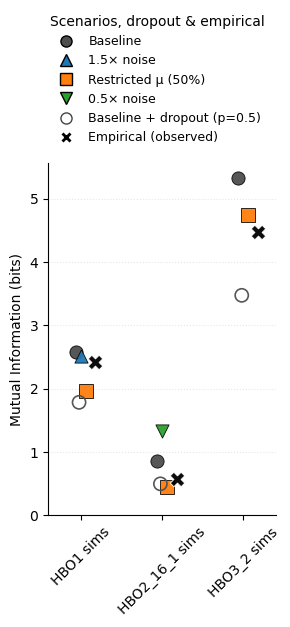

In [6]:
# --- Build data & plot (NO separate empirical column) ---

empirical_rows, sim_points = build_plot_data()

# Helper: lookup empirical MI per target dataset
empirical_MI = {}
for ds in TARGET_SIMS_ORDER:
    # find the empirical row for this dataset
    for row in empirical_rows:
        if row["dataset"] == ds:
            empirical_MI[ds] = row["MI"]
            break

# X positions: HBO1 | HBO2_16_1 | HBO3_2
x_positions = {
    f"{custom_titles.get('treutlein','treutlein')} sims":        0.0,
    f"{custom_titles.get('knoblich_day16_1','knoblich_day16_1')} sims": 1.0,
    f"{custom_titles.get('you2','you2')} sims":                   2.0,
}

EMPIRICAL_OFFSET = 0.18  # small offset to the right within each column so it doesn't overlap scenarios

plt.figure(figsize=(3, 6.4))
ax = plt.gca()

# --- Plot the simulation points (same as before) ---
for pt in sim_points:
    x = x_positions[pt["axis_label"]]
    base_name = pt["scenario"].replace(" + dropout (p=0.5)", "")
    base_offset = SCENARIO_OFFSETS.get(base_name, 0.0)
    offset = base_offset + (DROPOUT_NUDGE if pt["dropout"] else 0.0)

    if pt["dropout"]:
        # hollow marker for baseline+dropout
        ax.scatter(x + offset, pt["MI"], s=90, facecolors='none',
                   edgecolors=pt["color"], marker=pt["marker"],
                   linewidth=1.2, zorder=4, alpha=0.95)
    else:
        ax.scatter(x + offset, pt["MI"], s=90, color=pt["color"],
                   marker=pt["marker"], edgecolor="black",
                   linewidth=0.6, zorder=4, alpha=0.95)

# --- Add the empirical point inside each column ---
emp_handles_added = False
for ds in TARGET_SIMS_ORDER:
    axis_label = f"{custom_titles.get(ds, ds)} sims"
    x = x_positions[axis_label]
    y_emp = empirical_MI[ds]
    # choose a distinctive marker; keep it neutral (black)
    emp = ax.scatter(x + EMPIRICAL_OFFSET, y_emp, s=110, marker='X',
                     color='black', edgecolor='white', linewidth=0.7,
                     zorder=5, alpha=0.95)
    # we'll add a single legend entry for this marker later
    if not emp_handles_added:
        empirical_handle = Line2D([0],[0], marker='X', linestyle='',
                                  markerfacecolor='black', markeredgecolor='white',
                                  markersize=8, label="Empirical (observed)")
        emp_handles_added = True

# Axes / labels
ax.set_xlim(-0.4, 2.4)
ax.set_ylim(bottom=0)
ax.set_xticks([
    x_positions[f"{custom_titles.get('treutlein','treutlein')} sims"],
    x_positions[f"{custom_titles.get('knoblich_day16_1','knoblich_day16_1')} sims"],
    x_positions[f"{custom_titles.get('you2','you2')} sims"],
])
ax.set_xticklabels([
    f"{custom_titles.get('treutlein','treutlein')} sims",
    f"{custom_titles.get('knoblich_day16_1','knoblich_day16_1')} sims",
    f"{custom_titles.get('you2','you2')} sims",
])
ax.set_ylabel("Mutual Information (bits)")
ax.set_title("")

# Style
sns.despine()
ax.grid(axis='y', linestyle=':', alpha=0.3)

# Right legend: scenarios + dropout + empirical
# 1) scenario handles (filled)
scen_styles = {}
for ds, scen_list in SCENARIOS_BY_DATASET.items():
    for name, spec in scen_list:
        scen_styles[name] = (spec["marker"], spec["color"])
scen_handles = [Line2D([0],[0], marker=m, linestyle='',
                       markerfacecolor=c, markeredgecolor='black',
                       markersize=8, label=name)
                for name,(m,c) in scen_styles.items()]

# 2) dropout handle (hollow)
drop_handle = Line2D([0],[0], marker='o', linestyle='',
                     markerfacecolor='none', markeredgecolor='#444',
                     markersize=8, label="Baseline + dropout (p=0.5)")

# 3) empirical handle (black X)
legend_handles = scen_handles + [drop_handle]
if emp_handles_added:
    legend_handles.append(empirical_handle)

ax.legend(handles=legend_handles,
          title="Scenarios, dropout & empirical",
          bbox_to_anchor=(1.0, 1.02), loc="lower right",
          ncol=1, fontsize=9, frameon=False)

plt.xticks(rotation=45)


plt.tight_layout()

plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/simulation_gauss_expression.pdf", bbox_inches="tight")
plt.show()
